# Update 2 — RQ3: Paraphraser Fingerprints
**Member 4**

Can 23 linguistic features identify the T1 paraphraser? This notebook calls the existing `src/paraphraser_fingerprint.py` implementation and runs training, evaluation, visualization and validation.

Place this notebook in the repository's `notebooks/` directory. Install `requirements.txt` and download `data/processed/update2_features.pkl` before selecting **Restart Kernel and Run All**. `RQ3_PROJECT_ROOT` can optionally specify a different checkout.

Four target classes: ChatGPT, PaLM, default Dipper and Pegasus(full). The display label “Pegasus” always means Pegasus(full).

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

candidate = Path(os.environ.get("RQ3_PROJECT_ROOT", Path.cwd())).resolve()
PROJECT_ROOT = next((p for p in [candidate, *candidate.parents]
                     if (p / "src/paraphraser_fingerprint.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open from the repository root/notebooks, or set RQ3_PROJECT_ROOT.")
sys.path.insert(0, str(PROJECT_ROOT))
os.environ.setdefault("MPLBACKEND", "Agg")
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / "data/cache/matplotlib"))
from src.paraphraser_fingerprint import prepare_data, run, LABELS
from src.authorship_attribution import FEATURES, make_group_split

INPUT = PROJECT_ROOT / "data/processed/update2_features.pkl"
OUTPUT_ROOT = Path(os.environ.get("RQ3_OUTPUT_ROOT", PROJECT_ROOT)).resolve()
RESULTS = OUTPUT_ROOT / "data/results/update2"
FIGURES = OUTPUT_ROOT / "figures/update2"
assert INPUT.is_file(), f"Download processed features first: {INPUT}"
print("Project:", PROJECT_ROOT)
print("Input:", INPUT)


Project: <repository root>
Input: data/processed/update2_features.pkl


## 1. Data and four-class sample counts
The input contains complete T0–T3 chains. We select T1 only, exclude the extra intensity variants, and use linguistic features rather than document/source identifiers as predictors.

In [2]:
frame = pd.read_pickle(INPUT)
data = prepare_data(frame)
print(f"Full feature rows: {len(frame):,}; selected T1 rows: {len(data):,}")
print(f"Feature count: {len(FEATURES)}")
display(data.groupby("label").size().reindex(LABELS).rename("records").to_frame())
display(pd.crosstab(data.dataset, data.label).reindex(columns=LABELS))
display(pd.crosstab(data.source_group, data.label).reindex(columns=LABELS))
print("Missing feature cells in selected sample:", int(data[FEATURES].isna().sum().sum()))


Full feature rows: 530,636; selected T1 rows: 74,643
Feature count: 23
Missing feature cells in selected sample: 20


,records
label,
ChatGPT,19049
PaLM,16924
Dipper,19342
Pegasus,19328


label,ChatGPT,PaLM,Dipper,Pegasus
dataset,,,,
cmv,1603,1514,1626,1625
eli5,3128,3095,3160,3160
sci_gen,2738,1663,2797,2796
tldr,2416,2359,2444,2444
wp,2701,1968,2768,2763
xsum,3184,3053,3227,3220
yelp,3279,3272,3320,3320


label,ChatGPT,PaLM,Dipper,Pegasus
source_group,,,,
Human,2974,2386,3020,3018
LLM,16075,14538,16322,16310


## 2. Group isolation
Split `group_id = dataset::key` 80/20, stratified by dataset, seed 42. All source variants and paraphraser outputs of one document key remain on the same side. This does not rule out duplicate content under different keys.

In [3]:
train_ids, test_ids, assignments = make_group_split(data, test_size=0.20, random_state=42)
assert not train_ids & test_ids
assert train_ids | test_ids == set(data.group_id)
# Audit every stage/source/paraphraser in the full table, not only T1.
audit = frame.merge(assignments[["group_id", "split"]], on="group_id", validate="many_to_one")
assert audit.groupby(["dataset", "key"]).split.nunique().eq(1).all()
print("Train groups:", len(train_ids), "Test groups:", len(test_ids))
print("Group overlap:", len(train_ids & test_ids))
display(pd.crosstab(data.label, data.group_id.isin(test_ids)).rename(columns={False:"train", True:"test"}))


Train groups: 2416 Test groups: 604
Group overlap: 0


group_id,train,test
label,,
ChatGPT,15228,3821
Dipper,15469,3873
PaLM,13508,3416
Pegasus,15457,3871


## 3. Train and evaluate the existing implementation
Models: majority baseline, logistic regression and random forest. Median imputation fits training rows only. Logistic regression also uses training-only scaling. Random forest uses 200 trees, `min_samples_leaf=3`, balanced class weights. Hyperparameters are fixed, with no test-set tuning. This cell retrains all models and regenerates the result files.

In [4]:
summary = run(INPUT, RESULTS, FIGURES, seed=42)
assert summary["group_overlap"] == 0
metrics = pd.read_csv(RESULTS / "rq3_metrics.csv")
display(metrics)


Training majority_baseline: 59,662 train / 14,981 test
Training logistic_regression: 59,662 train / 14,981 test
Training random_forest: 59,662 train / 14,981 test
              model  n_train  n_test  accuracy  macro_f1
  majority_baseline    59662   14981  0.258527  0.102710
logistic_regression    59662   14981  0.591216  0.577600
      random_forest    59662   14981  0.638208  0.622506


,model,n_train,n_test,accuracy,macro_f1
0,majority_baseline,59662,14981,0.258527,0.102710
1,logistic_regression,59662,14981,0.591216,0.577600
2,random_forest,59662,14981,0.638208,0.622506


## 4. Confusion matrices and per-class errors
Rows indicate true labels, columns indicate predictions. The right panel normalizes rows and reports recall.

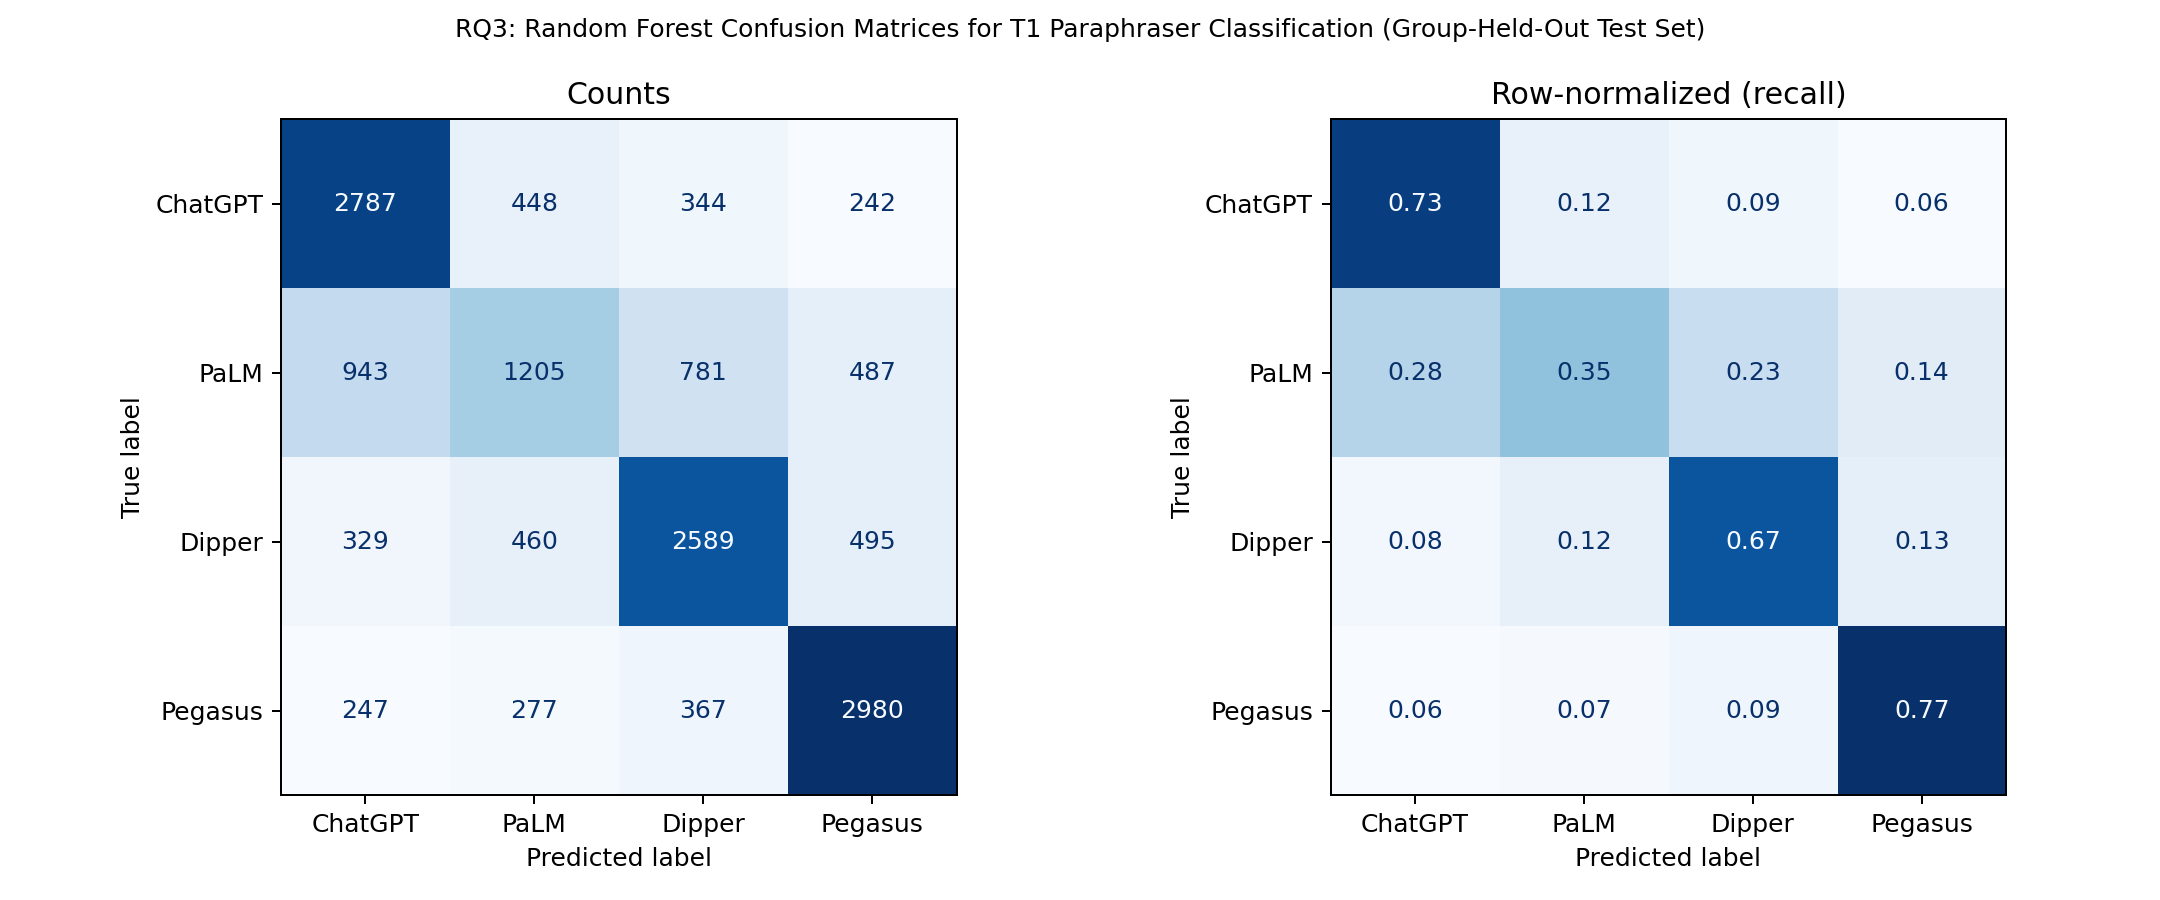

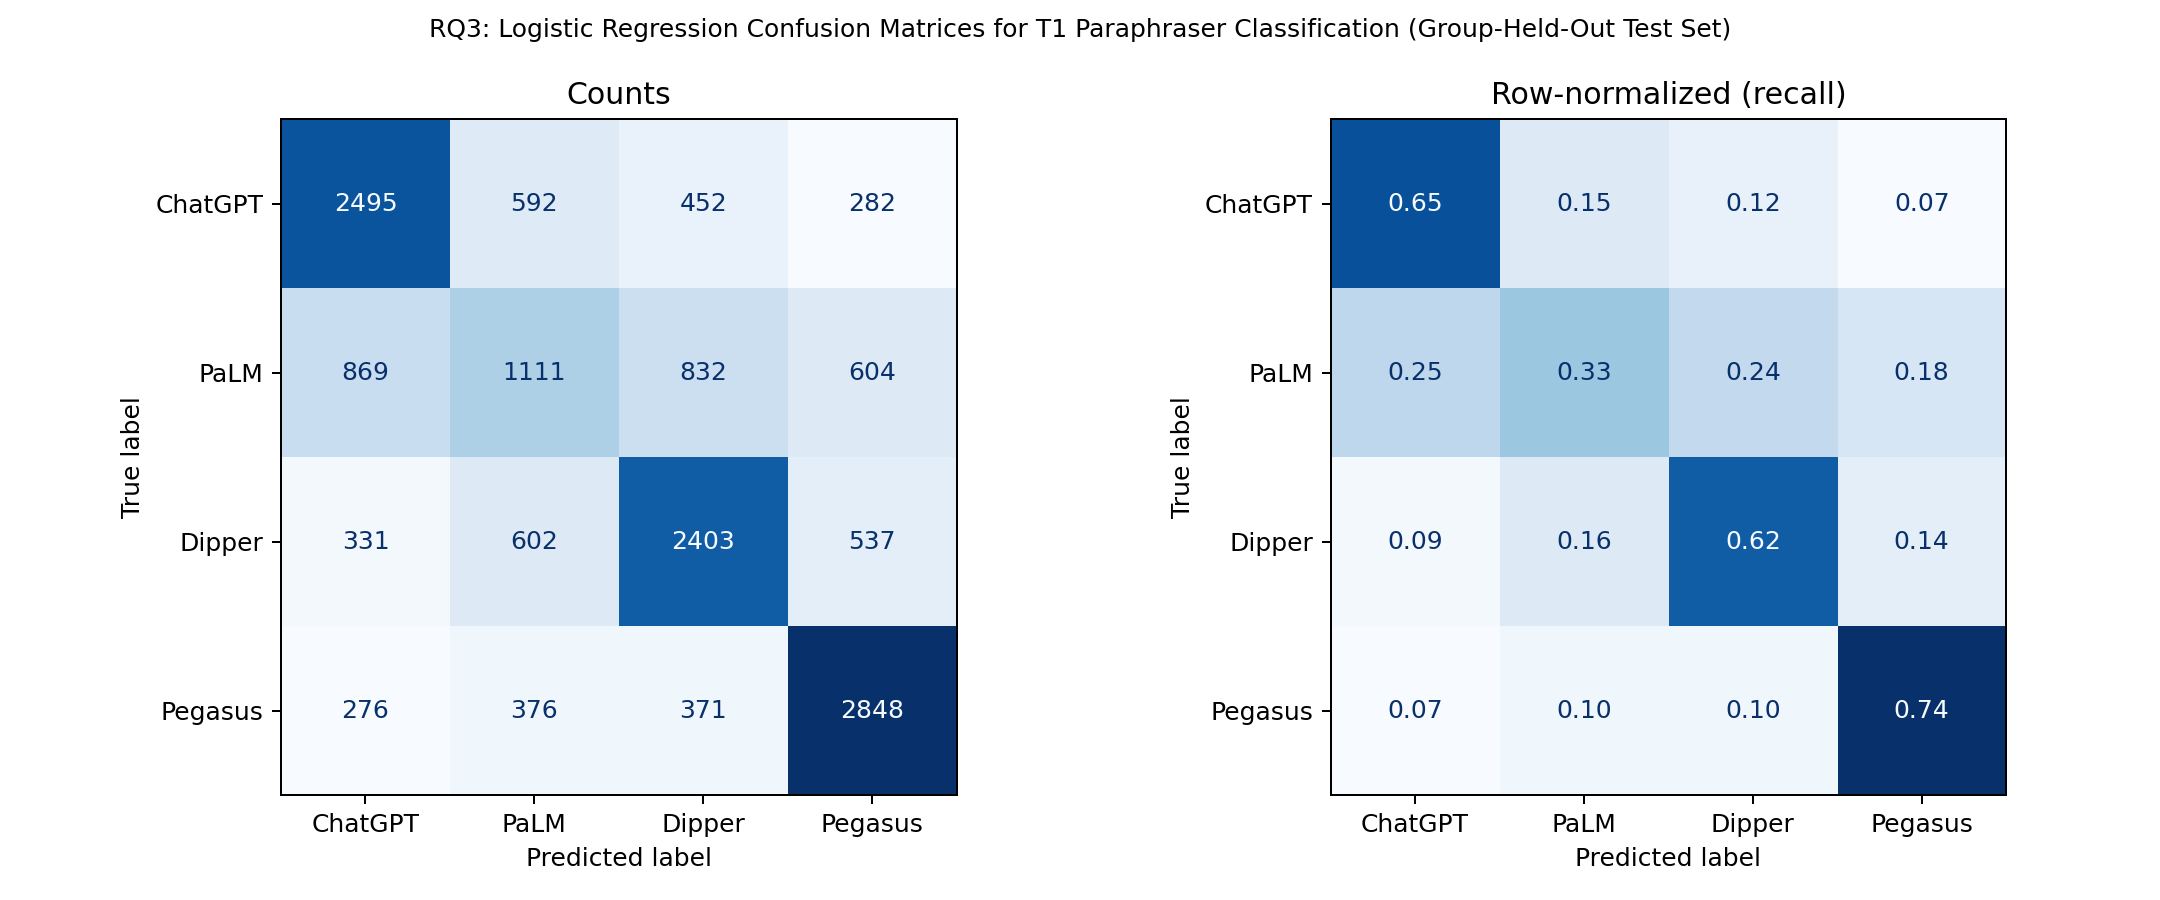

,class,precision,recall,f1-score,support
14,ChatGPT,0.647236,0.729390,0.685862,3821.0
15,PaLM,0.504184,0.352752,0.415088,3416.0
16,Dipper,0.634403,0.668474,0.650993,3873.0
17,Pegasus,0.708849,0.769827,0.738080,3871.0


predicted_label,ChatGPT,PaLM,Dipper,Pegasus
true_label,,,,
ChatGPT,2787,448,344,242
PaLM,943,1205,781,487
Dipper,329,460,2589,495
Pegasus,247,277,367,2980


In [5]:
display(Image(filename=str(FIGURES / "rq3_random_forest_confusion.png")))
display(Image(filename=str(FIGURES / "rq3_logistic_regression_confusion.png")))
reports = pd.read_csv(RESULTS / "rq3_classification_reports.csv")
rf = reports[(reports.model == "random_forest") & reports["class"].isin(LABELS)]
display(rf[["class", "precision", "recall", "f1-score", "support"]])
cm = pd.read_csv(RESULTS / "rq3_confusion_matrices.csv")
display(cm[cm.model.eq("random_forest")].pivot(index="true_label", columns="predicted_label", values="count").reindex(index=LABELS, columns=LABELS))


## 5. Preliminary distinguishing features
These standardized multinomial logistic coefficients explain the **logistic model**, not the random forest. Positive coefficients favor the corresponding class conditionally on other predictors. POS proportions are compositional, and several features correlate. These are exploratory associations, not causal or unique fingerprints.

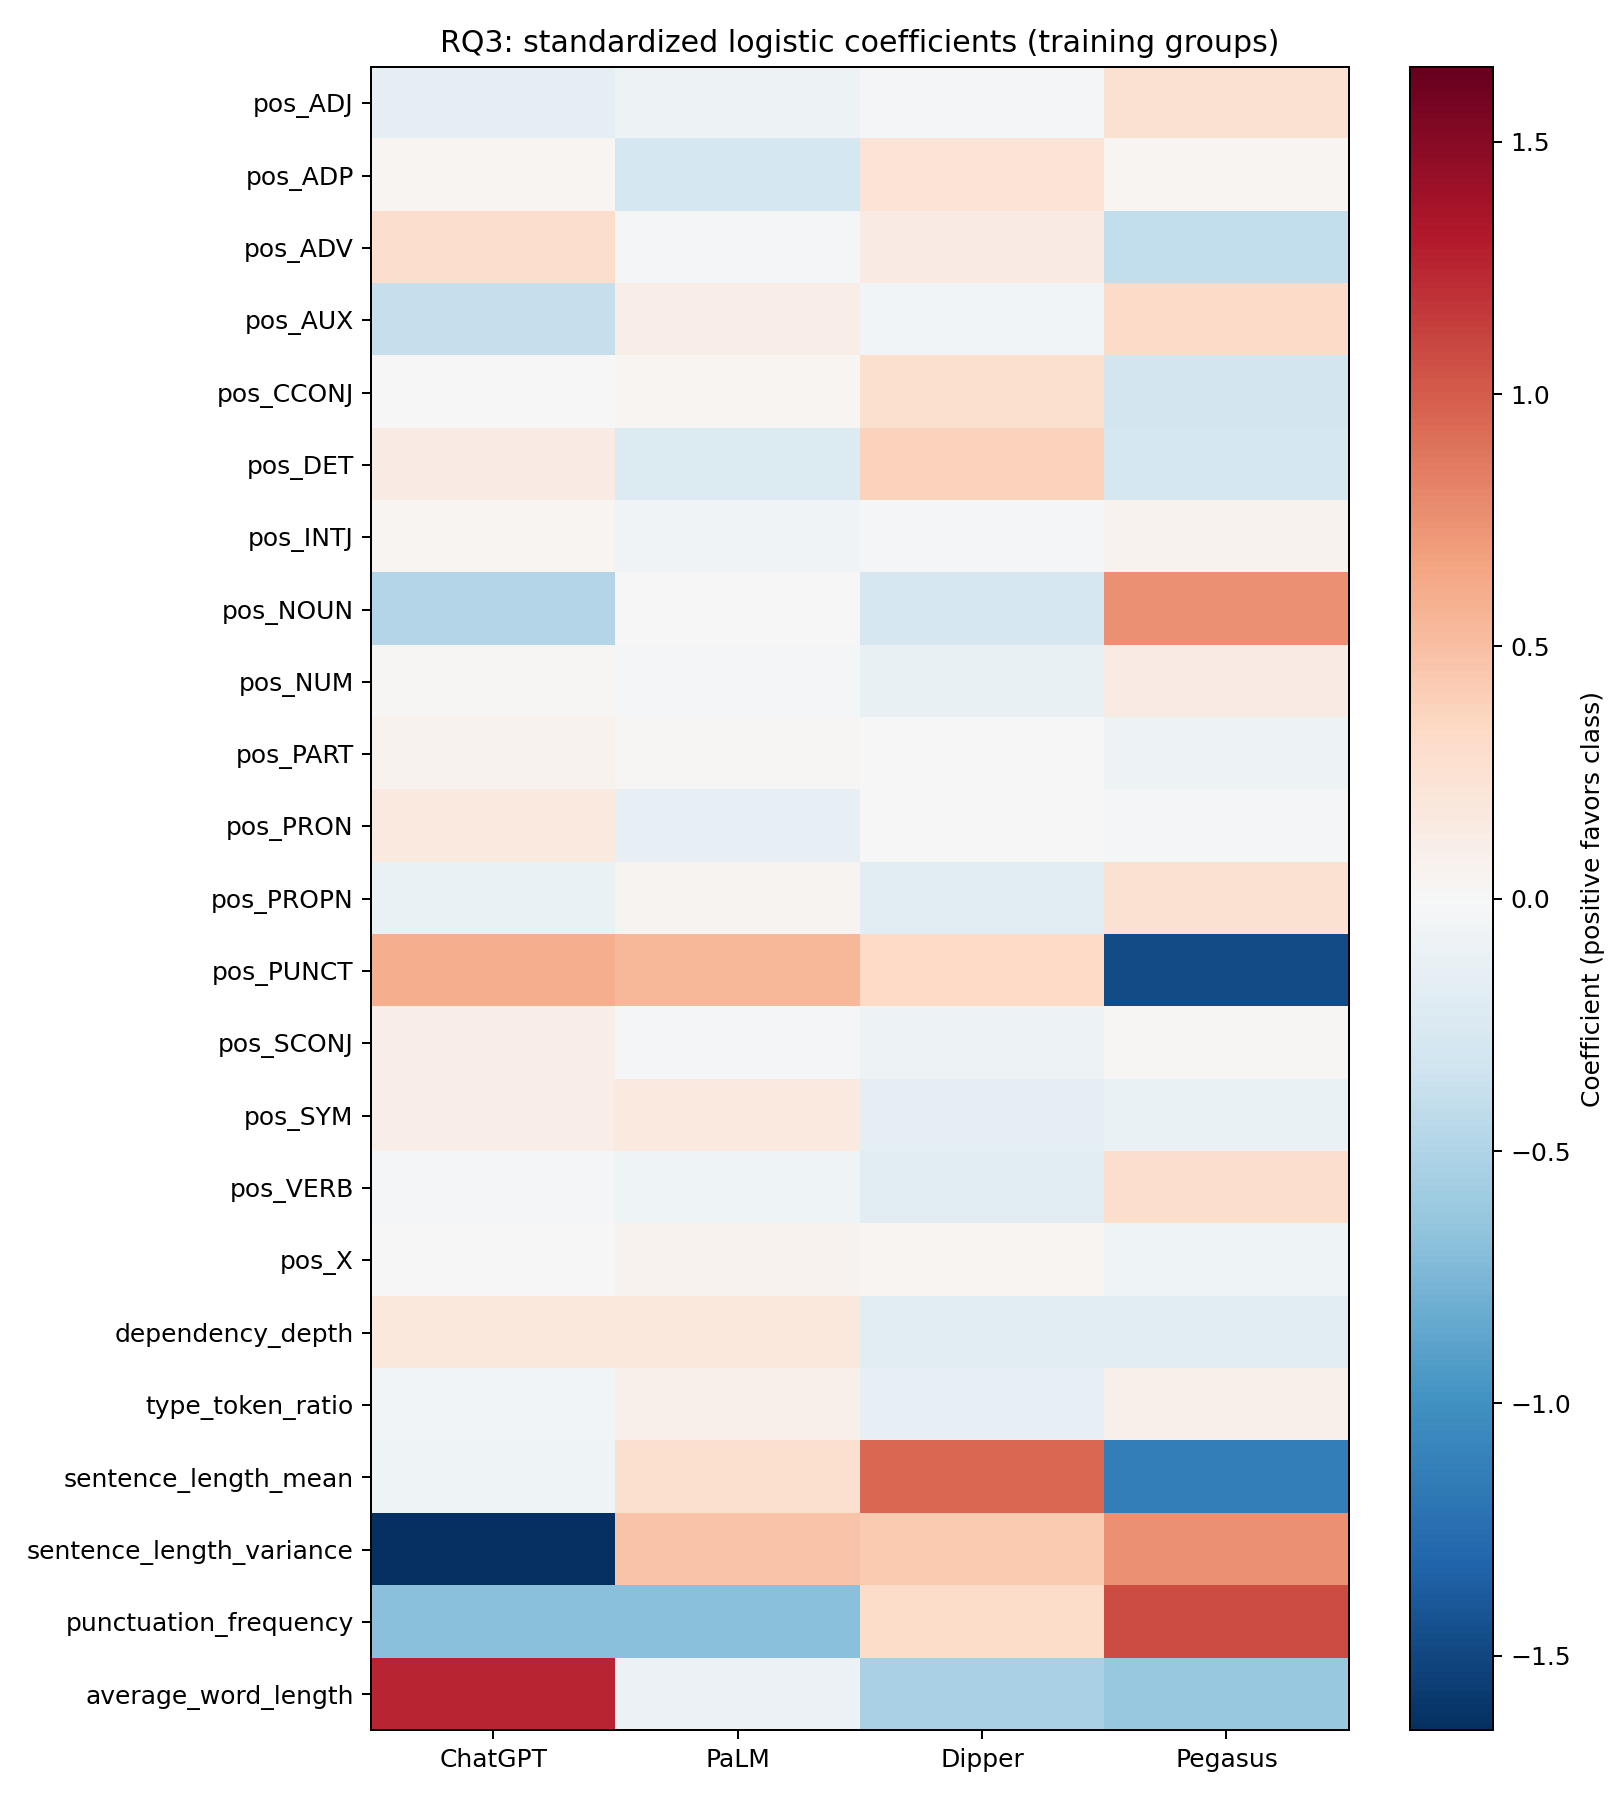

,label,feature,coefficient
0,ChatGPT,average_word_length,1.258061
1,ChatGPT,pos_PUNCT,0.601425
2,ChatGPT,pos_ADV,0.285454
3,ChatGPT,dependency_depth,0.178234
4,PaLM,pos_PUNCT,0.546332
5,PaLM,sentence_length_variance,0.465686
6,PaLM,sentence_length_mean,0.267616
7,PaLM,dependency_depth,0.169708
8,Dipper,sentence_length_mean,0.948248
9,Dipper,sentence_length_variance,0.429601


In [6]:
display(Image(filename=str(FIGURES / "rq3_feature_coefficients.png")))
coeff = pd.read_csv(RESULTS / "rq3_standardized_coefficients.csv", index_col="feature")
strongest = pd.concat([coeff[label].nlargest(4).rename("coefficient").reset_index().assign(label=label)
                       for label in LABELS], ignore_index=True)
display(strongest[["label", "feature", "coefficient"]])


## 6. Automated checks
Run the three dedicated RQ3 checks and the complete repository test suite. A nonzero return code stops the notebook.

In [7]:
import subprocess
for command in ([sys.executable, "-m", "tests.test_paraphraser_fingerprint"],
                [sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider"]):
    result = subprocess.run(command, cwd=PROJECT_ROOT, text=True, capture_output=True)
    print(result.stdout)
    if result.stderr:
        print(result.stderr)
    result.check_returncode()


3 RQ3 checks passed

.......................                                                  [100%]
23 passed in 0.99s



## 7. Result summary and limitations
Reference run: random forest accuracy **63.82%**, macro F1 **0.6225**. Logistic regression: **59.12% / 0.5776**. Majority baseline: **25.85% / 0.1027**.

PaLM is the weakest class by recall (about 35.3%). Of its 3,416 test records, 943 receive a ChatGPT prediction and 781 a Dipper prediction. Pegasus(full) has the highest recall (about 77.0%).

These results support distinguishable stylistic traces in the current sample. They use one group-disjoint T1 split, not external-domain evaluation or T2/T3 testing. Complete-chain filtering, source imbalance and parser quality may affect results. Pooled metrics include correlated rows within groups, and this experiment does not estimate confidence intervals.

The actual metrics and test outputs above are the authoritative results of this notebook run.